# Real-data validation: MultiClaim v1 / v2

Validation of the dated-corpus loader and answerability rates on the real
MultiClaim data.

**Where "the answer" comes from:** `fact_check_post_mapping.csv` records
which fact-check debunks which post — links the fact-checkers themselves
published (`relationship` = `claimreview_schema`, `backlink`,
`similarity:identical`). "Answerable" is a derived test on top of that
link: the linked fact-check's earliest timestamp is strictly before the
post's earliest timestamp, at full second precision ("everything published
before the post").

Raw CSVs live in the gitignored `data/raw/` tree; this notebook prints only
ids, counts, rates and dates — no post/claim text.

In [1]:
import csv
from collections import Counter
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt

from temporal_fact_checked_retrieval_eval.dataset import earliest_time
from temporal_fact_checked_retrieval_eval.dataset.multiclaim import load_multiclaim
from temporal_fact_checked_retrieval_eval.protocols import answerable, answerable_rate
from temporal_fact_checked_retrieval_eval.plotting import apply_style

def repo_root() -> Path:
    """Repo root: walk up from cwd until pyproject.toml is found."""
    here = Path.cwd().resolve()
    for parent in (here, *here.parents):
        if (parent / "pyproject.toml").exists():
            return parent
    raise FileNotFoundError("repo root not found above the working directory")

apply_style()

ROOT = repo_root() / "data" / "raw"

DATASETS = {
    "v1": {
        "fact_checks": ROOT / "multiclaim_v1" / "fact_checks.csv",
        "posts": ROOT / "multiclaim_v1" / "posts.csv",
        "mapping": ROOT / "multiclaim_v1" / "fact_check_post_mapping (1).csv",
    },
    "v2": {
        "fact_checks": ROOT / "multiclaim_v2" / "fact_checks.csv",
        "posts": ROOT / "multiclaim_v2" / "posts.csv",
        "mapping": ROOT / "multiclaim_v2" / "fact_check_post_mapping.csv",
    },
}

# Published counts from the paper, used only for the cross-check below.
PAPER_COUNTS = {
    "v1": {"fact_checks": 206_000, "posts": 28_000, "pairs": 31_305},
    "v2": {"fact_checks": 435_000, "posts": 89_000, "pairs": 105_000},
}


def csv_rows(path: Path) -> int:
    with path.open(newline="", encoding="utf-8-sig") as handle:
        return sum(1 for _ in csv.DictReader(handle))


def pair_times(corpus, pair):
    """Earliest full-precision timestamps of the fact-check and the post."""
    post = corpus.posts[pair.post_id]
    fact_check = corpus.fact_checks.get(pair.fact_check_id)
    post_time = earliest_time(post.instances)
    fact_check_time = earliest_time(fact_check.instances) if fact_check else None
    return fact_check_time, post_time


def answerable_counts(corpus, pairs=None):
    """Answerable counts over ``pairs`` (all by default).

    margin0 : fc_time < post_time            (full precision, primary)
    margin1 : fc_time < post_time - 1 day
    margin7 : fc_time < post_time - 7 days
    """
    pairs = corpus.pairs if pairs is None else pairs
    m0 = m1 = m7 = 0
    for pair in pairs:
        fc_time, post_time = pair_times(corpus, pair)
        if fc_time is None or post_time is None:
            continue
        if fc_time < post_time:
            m0 += 1
        if fc_time < post_time - timedelta(days=1):
            m1 += 1
        if fc_time < post_time - timedelta(days=7):
            m7 += 1
    return {"margin0": m0, "margin1": m1, "margin7": m7, "n": len(pairs)}

In [2]:
corpora = {
    name: load_multiclaim(
        fact_checks_csv=paths["fact_checks"],
        posts_csv=paths["posts"],
        mapping_csv=paths["mapping"],
    )
    for name, paths in DATASETS.items()
}

for name, corpus in corpora.items():
    print(f"loaded {name}: posts={len(corpus.posts):,} fact_checks={len(corpus.fact_checks):,} pairs={len(corpus.pairs):,}")

loaded v1: posts=25,957 fact_checks=205,751 pairs=29,020
loaded v2: posts=87,304 fact_checks=435,252 pairs=103,429


## 1. Row-count cross-check vs the paper

Reconcile raw CSV rows against what the loader returns:

- `loaded_posts + undated_dropped == total posts rows`
- `loaded_pairs + pairs_referencing_undated_posts == mapping rows`

In [3]:
for name in ("v1", "v2"):
    paths = DATASETS[name]
    corpus = corpora[name]

    fc_rows = csv_rows(paths["fact_checks"])
    post_rows = csv_rows(paths["posts"])
    mapping_rows = csv_rows(paths["mapping"])

    loaded_posts = len(corpus.posts)
    loaded_fact_checks = len(corpus.fact_checks)
    loaded_pairs = len(corpus.pairs)

    undated_dropped = post_rows - loaded_posts
    pairs_referencing_undated = mapping_rows - loaded_pairs
    paper = PAPER_COUNTS[name]

    print(f"=== {name} ===")
    print(f"  fact_checks.csv rows : {fc_rows:>8,}   (paper ~{paper['fact_checks']:,})")
    print(f"  posts.csv rows       : {post_rows:>8,}   (paper ~{paper['posts']:,})")
    print(f"  mapping rows         : {mapping_rows:>8,}   (paper ~{paper['pairs']:,})")
    print(f"  loader posts         : {loaded_posts:>8,}")
    print(f"  loader fact_checks   : {loaded_fact_checks:>8,}")
    print(f"  loader pairs         : {loaded_pairs:>8,}")
    print(f"  undated posts dropped: {undated_dropped:>8,}")
    print(f"  pairs->dropped posts : {pairs_referencing_undated:>8,}")
    ok_posts = loaded_posts + undated_dropped == post_rows
    ok_pairs = loaded_pairs + pairs_referencing_undated == mapping_rows
    print(f"  reconcile posts: {loaded_posts:,} + {undated_dropped:,} = {loaded_posts + undated_dropped:,} == {post_rows:,}  -> {ok_posts}")
    print(f"  reconcile pairs: {loaded_pairs:,} + {pairs_referencing_undated:,} = {loaded_pairs + pairs_referencing_undated:,} == {mapping_rows:,}  -> {ok_pairs}")
    print()

=== v1 ===
  fact_checks.csv rows :  205,751   (paper ~206,000)
  posts.csv rows       :   28,092   (paper ~28,000)
  mapping rows         :   31,305   (paper ~31,305)
  loader posts         :   25,957
  loader fact_checks   :  205,751
  loader pairs         :   29,020
  undated posts dropped:    2,135
  pairs->dropped posts :    2,285
  reconcile posts: 25,957 + 2,135 = 28,092 == 28,092  -> True
  reconcile pairs: 29,020 + 2,285 = 31,305 == 31,305  -> True

=== v2 ===
  fact_checks.csv rows :  435,252   (paper ~435,000)
  posts.csv rows       :   89,139   (paper ~89,000)
  mapping rows         :  105,424   (paper ~105,000)
  loader posts         :   87,304
  loader fact_checks   :  435,252
  loader pairs         :  103,429
  undated posts dropped:    1,835
  pairs->dropped posts :    1,995
  reconcile posts: 87,304 + 1,835 = 89,139 == 89,139  -> True
  reconcile pairs: 103,429 + 1,995 = 105,424 == 105,424  -> True



## 2. Answerable rate: full precision + day buffers

Primary (margin 0): `fc_time < post_time` at full second precision —
everything published before the post. The buffers show how much the number
would shrink if sub-day timestamps were untrustworthy:

- `margin 1 day` : `fc_time < post_time - 1 day`
- `margin 7 days`: `fc_time < post_time - 7 days`

`margin0` is cross-checked against `answerable_rate(corpus)`.

In [4]:
for name in ("v1", "v2"):
    corpus = corpora[name]
    res = answerable_counts(corpus)
    n = res["n"]
    api_rate = answerable_rate(corpus)
    print(f"=== {name} overall (n={n:,} pairs) ===")
    for label in ("margin0", "margin1", "margin7"):
        c = res[label]
        print(f"  {label:<10}: {c:>7,} / {n:,} = {c / n:.4%}")
    print(f"  answerable_rate() == margin0 -> {abs(api_rate - res['margin0'] / n) < 1e-12}")
    print()

=== v1 overall (n=29,020 pairs) ===
  margin0   :   4,307 / 29,020 = 14.8415%
  margin1   :   4,022 / 29,020 = 13.8594%
  margin7   :   3,821 / 29,020 = 13.1668%
  answerable_rate() == margin0 -> True

=== v2 overall (n=103,429 pairs) ===
  margin0   :   7,340 / 103,429 = 7.0967%
  margin1   :   2,720 / 103,429 = 2.6298%
  margin7   :   1,668 / 103,429 = 1.6127%
  answerable_rate() == margin0 -> True



In [5]:
def per_language(corpus, languages):
    """Margin0 counts and distinct answerable post count per post language."""
    out = {}
    for lang in languages:
        sub = [p for p in corpus.pairs if corpus.posts[p.post_id].language == lang]
        res = answerable_counts(corpus, sub)
        answerable_post_ids = set()
        for pair in sub:
            fc_time, post_time = pair_times(corpus, pair)
            if fc_time is not None and post_time is not None and fc_time < post_time:
                answerable_post_ids.add(pair.post_id)
        res["answerable_posts"] = len(answerable_post_ids)
        out[lang] = res
    return out


v2 = corpora["v2"]
for lang, res in per_language(v2, ["pol", "eng"]).items():
    n = res["n"]
    print(f"=== v2 {lang} (n={n:,} pairs) ===")
    print(f"  margin0         : {res['margin0']:>7,} / {n:,} = {res['margin0'] / n:.4%}")
    print(f"  answerable posts: {res['answerable_posts']:,}")
    print()

=== v2 pol (n=1,622 pairs) ===
  margin0         :     184 / 1,622 = 11.3440%
  answerable posts: 161

=== v2 eng (n=30,570 pairs) ===
  margin0         :   3,001 / 30,570 = 9.8168%
  answerable posts: 2,631



## 3. Relationship breakdown and same-day count (v2 only)

Answerable rate (margin 0, full precision) per `GoldPair.relationship`, plus
the number of pairs whose fact-check and post fall on the same calendar day
(`fc_time.date() == post_time.date()`) — the timestamp-sensitivity hot spot.

In [6]:
v2 = corpora["v2"]
rel_counts = Counter(p.relationship for p in v2.pairs)
print("=== v2 relationship -> answerable rate (margin 0) ===")
for rel in ("claimreview_schema", "backlink", "similarity:identical", None):
    n = rel_counts[rel]
    sub = [p for p in v2.pairs if p.relationship == rel]
    m0 = sum(1 for p in sub if answerable(v2, p))
    rate = m0 / n if n else 0.0
    print(f"  {rel!r:<22}: pairs={n:>6,}  answerable={m0:>6,}  rate={rate:.4%}")

same_day = 0
for pair in v2.pairs:
    fc_time, post_time = pair_times(v2, pair)
    if fc_time is not None and fc_time.date() == post_time.date():
        same_day += 1
total = len(v2.pairs)
print(f"=== v2 same-day pairs (fc.date() == post.date()): {same_day:,} / {total:,} = {same_day / total:.4%}")

=== v2 relationship -> answerable rate (margin 0) ===
  'claimreview_schema'  : pairs=38,234  answerable= 2,364  rate=6.1830%
  'backlink'            : pairs=57,734  answerable= 4,181  rate=7.2418%
  'similarity:identical': pairs= 7,461  answerable=   795  rate=10.6554%
  None                  : pairs=     0  answerable=     0  rate=0.0000%
=== v2 same-day pairs (fc.date() == post.date()): 6,679 / 103,429 = 6.4576%


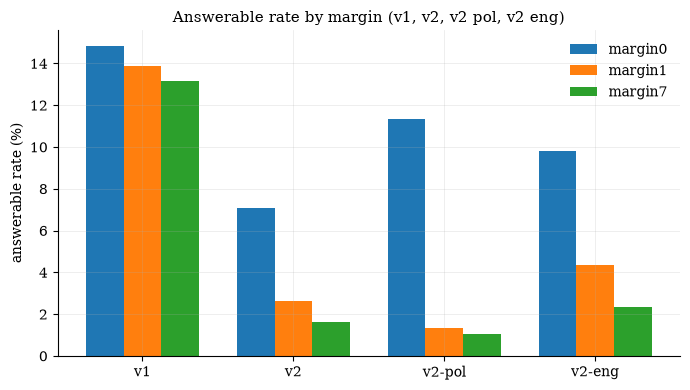

In [7]:
def rate(res, key):
    return res[key] / res["n"]


rows = {
    "v1": answerable_counts(corpora["v1"]),
    "v2": answerable_counts(corpora["v2"]),
    "v2-pol": per_language(corpora["v2"], ["pol"])["pol"],
    "v2-eng": per_language(corpora["v2"], ["eng"])["eng"],
}
margins = ["margin0", "margin1", "margin7"]

fig, ax = plt.subplots(figsize=(7, 4))
x = range(len(rows))
width = 0.25
for i, m in enumerate(margins):
    vals = [rate(rows[k], m) * 100 for k in rows]
    ax.bar([xi + (i - 1) * width for xi in x], vals, width, label=m)
ax.set_xticks(list(x))
ax.set_xticklabels(rows.keys())
ax.set_ylabel("answerable rate (%)")
ax.set_title("Answerable rate by margin (v1, v2, v2 pol, v2 eng)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show(block=False)